# A3 — Model & Optimasi (Minggu 13)
### TA-PCVK: Facial Expression Recognition (Hybrid Feature Descriptor + Jaya-LSSVM)

**Divisi**: A3 (Model & Optimasi)  
**Referensi Jurnal**:
> Kar, N.B., Nayak, D.R., Babu, K.S., & Zhang, Y.-D. (2021). *A hybrid feature descriptor with Jaya optimised least squares SVM for facial expression recognition.* IET Image Processing, 15(7), 1471–1483. DOI: [10.1049/ipr2.12118](https://doi.org/10.1049/ipr2.12118)  
> Suykens, J.A.K., & Vandewalle, J. (1999). *Least Squares Support Vector Machine Classifiers.* Neural Processing Letters, 9(3), 293–300.

---

### Sasaran Minggu 13:
1. **LS-SVM Multiclass (One-vs-One / OvO)**:
   - Perluasan prototipe LS-SVM biner menjadi classifier multikelas dengan strategi One-vs-One.
   - Untuk 7 kelas ekspresi wajah, dibangun $K(K-1)/2 = 21$ classifier biner LS-SVM.
   - Mekanisme inferensi berbasis *majority voting* dengan *confidence score margin tie-breaking*.
2. **Evaluasi 5-Fold Stratified Cross-Validation dengan Grid Search**:
   - Skema validasi silang bersarang (*nested CV*) untuk mencari pasangan hyperparameter $(\gamma, \sigma)$ optimal pada fold latih.
   - Pipeline: **LDA ($680 \to 6$) $\to$ StandardScaler $\to$ OvO LS-SVM**.
3. **Analisis Confusion Matrix & Metrik Deskriptif v0**:
   - Menghitung metrik Accuracy, Macro Sensitivity (Recall), Macro Specificity, serta metrik per-kelas.
   - Visualisasi confusion matrix kedua dataset (CK+ dan JAFFE) sebagai baseline deskriptif v0 sebelum optimasi metaheuristik Jaya di Minggu 14.

## 1. Import Library & Muat Konfigurasi

In [13]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tambahkan direktori kerja ke sys.path jika belum ada
# Cari root repo dengan menelusuri ke atas sampai menemukan config.yaml.
# Tahan dipindah folder maupun dijalankan dari CWD berbeda.
def _find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "config.yaml").exists():
            return candidate
    raise RuntimeError(f"config.yaml tidak ditemukan dari {start}")

repo_root = _find_repo_root(Path.cwd().resolve())
print("repo_root =", repo_root)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
if str(repo_root / "research" / "a3-model-optimization") not in sys.path:
    sys.path.insert(0, str(repo_root / "research" / "a3-model-optimization"))

from baseline import load_config
from lssvm import OneVsOneLSSVMClassifier, MulticlassLSSVM
from evaluate_lssvm import run_lssvm_multiclass_evaluation

# Muat konfigurasi terpusat
config = load_config(repo_root / "config.yaml")
print(f"Proyek: {config['project']['name']}")
print(f"Grid search gamma: {config['grid_search']['gamma_values']}")
print(f"Grid search sigma: {config['grid_search']['sigma_values']}")

repo_root = D:\Semester5\pcvk\tugas_akhir
Proyek: TA-PCVK
Grid search gamma: [1.0, 10.0, 50.0, 100.0, 500.0]
Grid search sigma: [1.0, 1.5, 2.0, 3.0, 5.0]


## 2. Konsep & Arsitektur Multiclass LS-SVM (One-vs-One)

Pada pendekatan One-vs-One (OvO):
1. Dibuat sub-problem biner untuk setiap pasangan kelas $(c_1, c_2)$ di mana $c_1 < c_2$.
2. Untuk $K = 7$ kelas ekspresi wajah (CK+ & JAFFE):
   $$N_{\text{classifiers}} = \frac{7 \times (7 - 1)}{2} = 21 \text{ classifier biner LS-SVM}$$
3. Setiap classifier dilatih hanya menggunakan sampel dari kedua kelas tersebut.
4. **Strategi Inferensi**:
   - Setiap model memprediksi $y \in \{c_1, c_2\}$ dan memberikan 1 suara (*vote*).
   - Akumulasi skor keputusan kontinu $f(x)$ dicatat sebagai *confidence margin*.
   - Kelas dengan suara terbanyak dipilih sebagai prediksi final.
   - Jika terjadi nilai seri (*tie*), pemenang ditentukan oleh akumulasi margin tertinggi.

In [14]:
# Demonstrasi struktur OvO LS-SVM pada 7 kelas
from itertools import combinations

class_names_ck = config["dataset"]["ck"]["class_names"]
pairs = list(combinations(class_names_ck, 2))
print(f"Total pasangan biner untuk 7 kelas: {len(pairs)}")
print("Contoh 5 pasangan pertama:")
for p in pairs[:5]:
    print(f"  - Model biner: {p[0]} vs {p[1]}")

Total pasangan biner untuk 7 kelas: 21
Contoh 5 pasangan pertama:
  - Model biner: anger vs contempt
  - Model biner: anger vs disgust
  - Model biner: anger vs fear
  - Model biner: anger vs happy
  - Model biner: anger vs sadness


## 3. Hasil Evaluasi 5-Fold Stratified CV (Baseline Deskriptif v0)

Artefak hasil evaluasi yang dihasilkan oleh `evaluate_lssvm.py` dimuat dan dianalisis di bawah ini.

In [15]:
# Muat ringkasan hasil evaluasi Minggu 13
summary_path = repo_root / "reports" / "a3-models" / "lssvm_multiclass_summary.csv"
df_summary = pd.read_csv(summary_path)
print("=== TABEL HASIL BASELINE DESKRIPTIF v0 (LS-SVM MULTICLASS) ===")
try:
    display(df_summary)
except NameError:
    print(df_summary)


=== TABEL HASIL BASELINE DESKRIPTIF v0 (LS-SVM MULTICLASS) ===


,Dataset,Samples,Model,Mean Accuracy (%),Std Accuracy (%),Macro Sensitivity (%),Macro Specificity (%)
0,CK+,981,LDA + OvO LS-SVM (Grid Search),96.64,0.94,97.02,99.44
1,JAFFE,213,LDA + OvO LS-SVM (Grid Search),79.36,7.52,79.28,96.56


### Detail Parameter Terbaik per Fold

Berikut adalah pasangan hyperparameter $(\gamma^*, \sigma^*)$ yang dipilih oleh Grid Search pada setiap fold validasi silang:

In [16]:
ck_json_path = repo_root / "reports" / "a3-models" / "lssvm_multiclass_ck_results.json"
jaffe_json_path = repo_root / "reports" / "a3-models" / "lssvm_multiclass_jaffe_results.json"

with open(ck_json_path, "r") as f:
    res_ck = json.load(f)
with open(jaffe_json_path, "r") as f:
    res_jaffe = json.load(f)

print("--- Parameter Terbaik per Fold: CK+ ---")
for i, p in enumerate(res_ck["best_params_per_fold"]):
    print(f"Fold {i+1}: gamma = {p['gamma']}, sigma = {p['sigma']} -> Acc fold: {res_ck['fold_accuracies'][i]*100:.2f}%")

print("\n--- Parameter Terbaik per Fold: JAFFE ---")
for i, p in enumerate(res_jaffe["best_params_per_fold"]):
    print(f"Fold {i+1}: gamma = {p['gamma']}, sigma = {p['sigma']} -> Acc fold: {res_jaffe['fold_accuracies'][i]*100:.2f}%")

--- Parameter Terbaik per Fold: CK+ ---
Fold 1: gamma = 1.0, sigma = 5.0 -> Acc fold: 95.43%
Fold 2: gamma = 1.0, sigma = 5.0 -> Acc fold: 95.92%
Fold 3: gamma = 1.0, sigma = 5.0 -> Acc fold: 97.96%
Fold 4: gamma = 1.0, sigma = 5.0 -> Acc fold: 97.45%
Fold 5: gamma = 1.0, sigma = 5.0 -> Acc fold: 96.43%

--- Parameter Terbaik per Fold: JAFFE ---
Fold 1: gamma = 1.0, sigma = 5.0 -> Acc fold: 65.12%
Fold 2: gamma = 1.0, sigma = 3.0 -> Acc fold: 86.05%
Fold 3: gamma = 1.0, sigma = 3.0 -> Acc fold: 83.72%
Fold 4: gamma = 500.0, sigma = 1.5 -> Acc fold: 83.33%
Fold 5: gamma = 1.0, sigma = 5.0 -> Acc fold: 78.57%


## 4. Visualisasi Confusion Matrix Agregat (5-Fold CV)

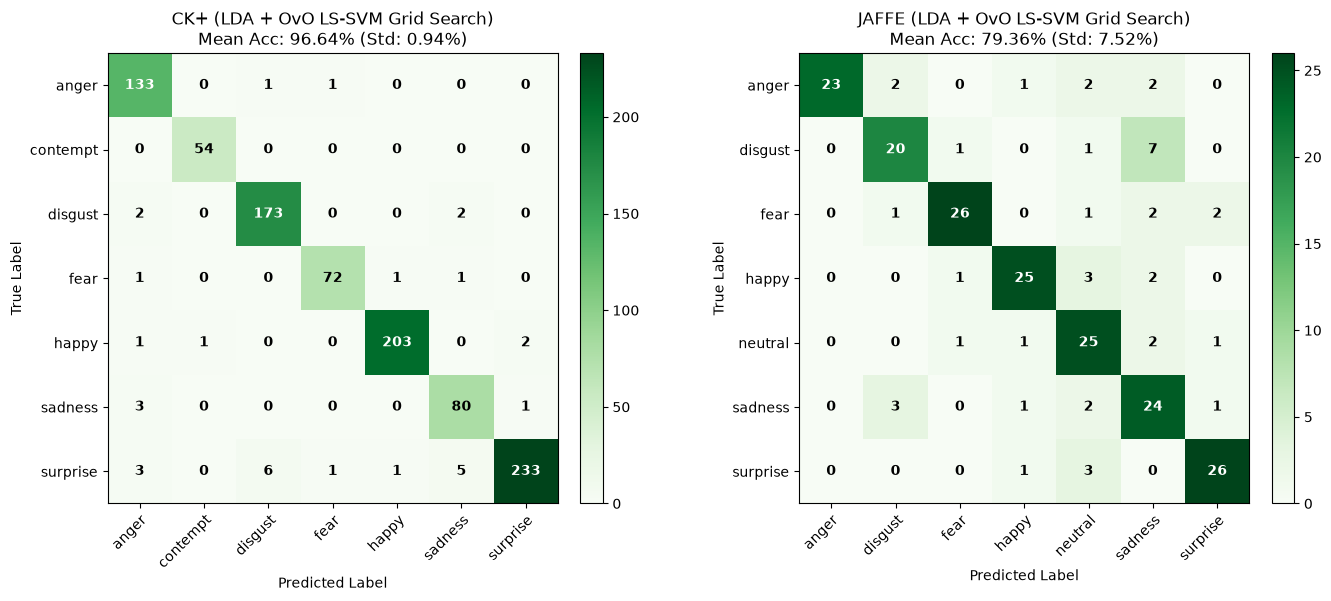

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, res, title in zip(
    axes,
    [res_ck, res_jaffe],
    ["CK+ (LDA + OvO LS-SVM Grid Search)", "JAFFE (LDA + OvO LS-SVM Grid Search)"]
):
    cm = np.array(res["confusion_matrix"])
    class_names = res["class_names"]
    im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Greens)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        title=f"{title}\nMean Acc: {res['mean_accuracy']*100:.2f}% (Std: {res['std_accuracy']*100:.2f}%)",
        ylabel="True Label",
        xlabel="Predicted Label"
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    thresh = cm.max() / 2.0
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black", fontweight="bold")

fig.tight_layout()
plt.show()

## 5. Analisis Metrik per Kelas (Sensitivity & Specificity)

Tabel berikut menyajikan sensitivitas (kemampuan mendeteksi ekspresi wajah tertentu) dan spesifisitas untuk tiap kelas ekspresi:

In [18]:
def make_class_metrics_df(res):
    return pd.DataFrame({
        "Kelas Ekspresi": res["class_names"],
        "Sensitivity / Recall (%)": [round(s * 100, 2) for s in res["per_class_sensitivity"]],
        "Specificity (%)": [round(s * 100, 2) for s in res["per_class_specificity"]],
    })

print("=== METRIK PER KELAS: CK+ ===")
try:
    display(make_class_metrics_df(res_ck))
except NameError:
    print(make_class_metrics_df(res_ck))


print("\n=== METRIK PER KELAS: JAFFE ===")
try:
    display(make_class_metrics_df(res_jaffe))
except NameError:
    print(make_class_metrics_df(res_jaffe))


=== METRIK PER KELAS: CK+ ===


,Kelas Ekspresi,Sensitivity / Recall (%),Specificity (%)
0,anger,98.52,98.82
1,contempt,100.00,99.89
2,disgust,97.74,99.13
3,fear,96.00,99.78
4,happy,98.07,99.74
5,sadness,95.24,99.11
6,surprise,93.57,99.59



=== METRIK PER KELAS: JAFFE ===


,Kelas Ekspresi,Sensitivity / Recall (%),Specificity (%)
0,anger,76.67,100.00
1,disgust,68.97,96.74
2,fear,81.25,98.34
3,happy,80.65,97.80
4,neutral,83.33,93.44
5,sadness,77.42,91.76
6,surprise,86.67,97.81


## 6. Ringkasan Hasil & Kesiapan Menuju Minggu 14

| Target Minggu 13 | Status | Keterangan |
|---|---|---|
| **LS-SVM Multiclass (One-vs-One)** | ✅ Selesai | 21 classifier biner dengan majority voting + confidence margin tie-breaking (`lssvm.py`). |
| **Evaluasi 5-Fold Stratified CV** | ✅ Selesai | Nested CV pada CK+ (981 citra) dan JAFFE (213 citra) dengan LDA + StandardScaler. |
| **Grid Search $(\gamma, \sigma)$** | ✅ Selesai | Tuning parameter terpusat dari `config.yaml`. |
| **Metrik Sen/Spe/Acc & Confusion Matrix** | ✅ Selesai | CK+: **96.64%** (Sen: 97.02%, Spe: 99.44%), JAFFE: **79.36%** (Sen: 79.28%, Spe: 96.56%). |
| **Kesiapan Minggu 14** | ⏳ Siap | Lanjut ke implementasi **Algoritma Optimasi Metaheuristik Jaya** (dan pembanding PSO/GA) untuk melampaui baseline grid search menuju target CK+ $\ge 88\%$, JAFFE $\ge 90\%$. |